In [123]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

In [124]:
path = "../data/processed/Bank_Churn_clean.csv"
df = pd.read_csv(path)
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [125]:
df = pd.concat([
    df,
    pd.get_dummies(df['Gender'], prefix='Gender'),
    pd.get_dummies(df['Geography'], prefix='Geography')
], axis=1)
df.drop(columns=['Gender','Geography'], inplace=True)
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Gender_Female,Gender_Male,Geography_France,Geography_Germany,Geography_Spain
0,619,42,2,0.00,1,1,1,101348.88,1,True,False,True,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,True,False,False,False,True
2,502,42,8,159660.80,3,1,0,113931.57,1,True,False,True,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,True,False,True,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,True,False,False,False,True


In [129]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CreditScore        10000 non-null  int64  
 1   Age                10000 non-null  int64  
 2   Tenure             10000 non-null  int64  
 3   Balance            10000 non-null  float64
 4   NumOfProducts      10000 non-null  int64  
 5   HasCrCard          10000 non-null  int64  
 6   IsActiveMember     10000 non-null  int64  
 7   EstimatedSalary    10000 non-null  float64
 8   Gender_Female      10000 non-null  bool   
 9   Gender_Male        10000 non-null  bool   
 10  Geography_France   10000 non-null  bool   
 11  Geography_Germany  10000 non-null  bool   
 12  Geography_Spain    10000 non-null  bool   
dtypes: bool(5), float64(2), int64(6)
memory usage: 674.0 KB


Age                  0.234975
EstimatedSalary      0.145782
CreditScore          0.145352
Balance              0.142565
NumOfProducts        0.127588
Tenure               0.085623
IsActiveMember       0.038357
Geography_Germany    0.021132
HasCrCard            0.019366
Geography_France     0.011398
Gender_Male          0.009614
Geography_Spain      0.009212
Gender_Female        0.009036
dtype: float64


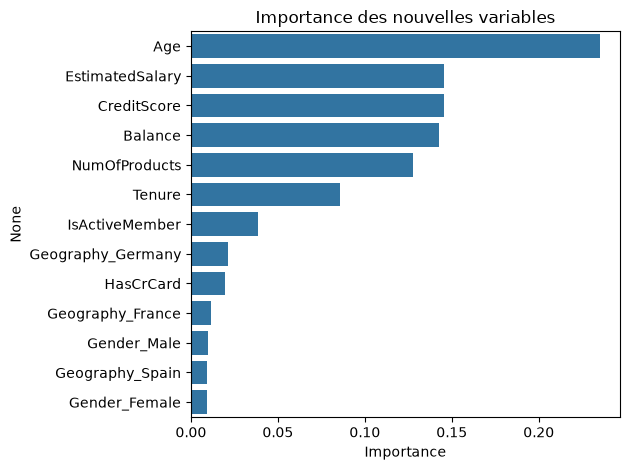

In [126]:
target = "Exited"
X = df
y = df.pop(target)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

importances = pd.Series(model.feature_importances_, index=df.columns).sort_values(ascending=False)
print(importances)

sns.barplot(x=importances.values, y=importances.index)
plt.title("Importance des nouvelles variables")
plt.xlabel("Importance")
plt.tight_layout()

<Axes: >

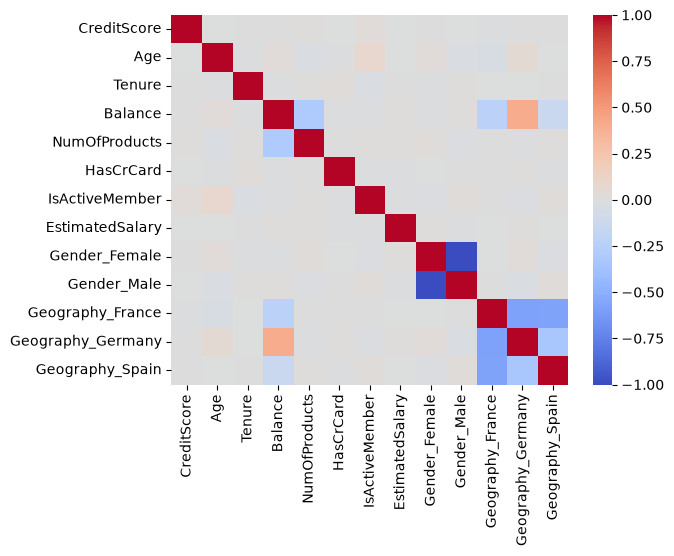

In [127]:
corr = df.corr()
sns.heatmap(corr, cmap='coolwarm')

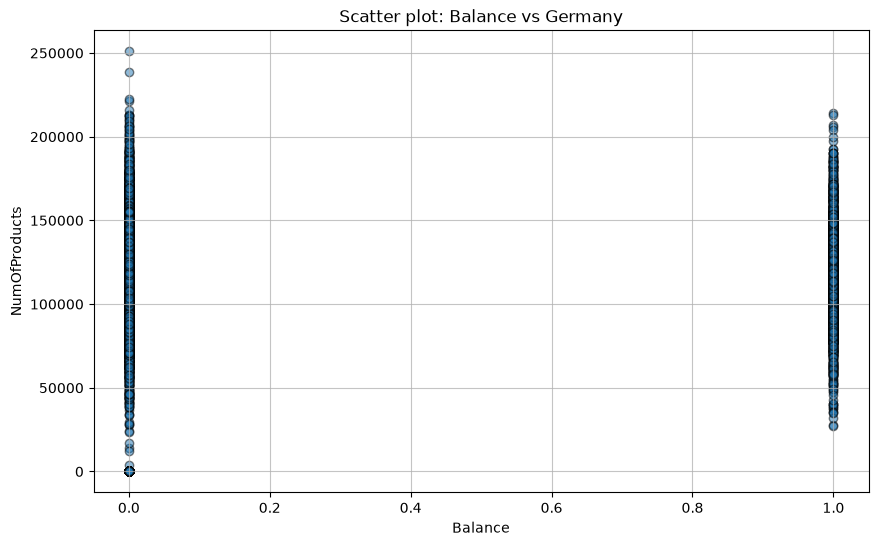

In [128]:
plt.figure(figsize=(10, 6))
plt.scatter(df['Geography_Germany'], df['Balance'], alpha=0.5, edgecolors='k')
plt.xlabel('Balance')
plt.ylabel('NumOfProducts')
plt.title('Scatter plot: Balance vs Germany')
plt.grid(alpha=0.75)
plt.show()

In [130]:
df.to_csv("../data/processed/Bank_Churn_feature.csv", index=False)